# BlueStock Mutual Fund Analysis

## Day 3 – Exploratory Data Analysis (EDA)

### Objective

This notebook performs Exploratory Data Analysis (EDA) on the BlueStock Mutual Fund dataset.

The analysis includes:

- Daily NAV Trends
- Assets Under Management (AUM)
- SIP Inflows
- Category-wise Inflows
- Investor Demographics
- Geographic Distribution
- Folio Growth
- Correlation Analysis
- Sector Allocation

The objective is to generate business insights through interactive visualizations and statistical analysis.

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

# Style
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Libraries Imported Successfully")

Libraries Imported Successfully


# Load Datasets

In [5]:
fund_master = pd.read_csv("../data/raw/01_fund_master.csv")

nav = pd.read_csv("../data/processed/02_nav_history_cleaned.csv")

aum = pd.read_csv("../data/raw/03_aum_by_fund_house.csv")

sip = pd.read_csv("../data/raw/04_monthly_sip_inflows.csv")

category = pd.read_csv("../data/raw/05_category_inflows.csv")

folio = pd.read_csv("../data/raw/06_industry_folio_count.csv")

performance = pd.read_csv("../data/processed/07_scheme_performance_cleaned.csv")

transactions = pd.read_csv("../data/processed/08_investor_transactions_cleaned.csv")

portfolio = pd.read_csv("../data/raw/09_portfolio_holdings.csv")

benchmark = pd.read_csv("../data/raw/10_benchmark_indices.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


# Data Preprocessing

In [6]:
nav["date"] = pd.to_datetime(nav["date"])

aum["date"] = pd.to_datetime(aum["date"])

sip["month"] = pd.to_datetime(sip["month"])

category["month"] = pd.to_datetime(category["month"])

folio["month"] = pd.to_datetime(folio["month"])

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

print("Date conversion completed successfully.")

Date conversion completed successfully.


# Dataset Overview

In [7]:
datasets = {
    "Fund Master": fund_master,
    "NAV History": nav,
    "AUM": aum,
    "SIP": sip,
    "Category": category,
    "Folio": folio,
    "Performance": performance,
    "Transactions": transactions,
    "Portfolio": portfolio,
    "Benchmark": benchmark
}

for name, df in datasets.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Shape :", df.shape)
    print(df.head(3))

Fund Master
Shape : (40, 15)
   amfi_code       fund_house                                 scheme_name  \
0     119551  SBI Mutual Fund   SBI Bluechip Fund - Regular Plan - Growth   
1     119552  SBI Mutual Fund    SBI Bluechip Fund - Direct Plan - Growth   
2     119598  SBI Mutual Fund  SBI Small Cap Fund - Regular Plan - Growth   

  category sub_category     plan launch_date             benchmark  \
0   Equity    Large Cap  Regular  2006-02-14         NIFTY 100 TRI   
1   Equity    Large Cap   Direct  2013-01-01         NIFTY 100 TRI   
2   Equity    Small Cap  Regular  2009-09-09  BSE 250 SmallCap TRI   

   expense_ratio_pct  exit_load_pct  min_sip_amount  min_lumpsum_amount  \
0               1.54            1.0             500                1000   
1               0.66            1.0             500                1000   
2               1.43            1.0             500                1000   

    fund_manager risk_category sebi_category_code  
0  Sohini Andani      Modera

# 1. Daily NAV Trend Analysis

### Objective

This visualization shows the daily Net Asset Value (NAV) movement of all mutual fund schemes from **2022 to 2026**.

The chart highlights two important market phases:

- 2023 Bull Run
- 2024 Market Correction

This helps understand how different mutual fund schemes behaved during changing market conditions.

In [8]:
print(nav.columns)

print("\nNumber of Schemes :", nav["amfi_code"].nunique())

print("\nDate Range")
print(nav["date"].min())
print(nav["date"].max())

Index(['amfi_code', 'date', 'nav'], dtype='str')

Number of Schemes : 40

Date Range
2022-01-03 00:00:00
2026-05-29 00:00:00


In [9]:
nav_plot = nav.merge(
    fund_master[["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

nav_plot.head()

,amfi_code,date,nav,scheme_name
0,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
1,100016,2022-01-04,515.0971,HDFC Top 100 Fund - Regular Plan - Growth
2,100016,2022-01-05,521.7239,HDFC Top 100 Fund - Regular Plan - Growth
3,100016,2022-01-06,515.7880,HDFC Top 100 Fund - Regular Plan - Growth
4,100016,2022-01-07,515.1639,HDFC Top 100 Fund - Regular Plan - Growth


In [10]:
fig = px.line(
    nav_plot,
    x="date",
    y="nav",
    color="scheme_name",
    title="Daily NAV Trend of Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "NAV",
        "scheme_name": "Scheme"
    }
)

fig.update_layout(
    height=700,
    width=1200,
    template="plotly_white",
    title_x=0.5,
    hovermode="x unified"
)

fig.show()

In [11]:
fig.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.15,
    line_width=0,
    annotation_text="2023 Bull Run",
    annotation_position="top left"
)

fig.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="red",
    opacity=0.12,
    line_width=0,
    annotation_text="2024 Market Correction",
    annotation_position="top right"
)

fig.show()

In [12]:
fig.write_html("../charts/nav/nav_trend_analysis.html")

print("NAV Trend chart saved successfully!")

NAV Trend chart saved successfully!


## Business Insight 1

- The majority of mutual fund schemes displayed a steady upward trend in NAV during **2023**, indicating a strong bull market.
- A noticeable slowdown and correction was observed during 2024, reflecting changing market conditions.
- Despite the correction, most long-term schemes maintained an overall positive growth trajectory.

In [13]:
## top 10 scheme
latest_nav = (
    nav_plot.sort_values("date")
    .groupby("scheme_name")
    .tail(1)
    .sort_values("nav", ascending=False)
)

latest_nav.head(10)

,amfi_code,date,nav,scheme_name
36799,120844,2026-05-29,4268.5497,Kotak Liquid Fund - Regular - Growth
37949,125497,2026-05-29,1204.9571,HDFC Top 100 Fund - Direct Plan - Growth
4599,101206,2026-05-29,773.2939,ABSL Frontline Equity Fund - Regular - Growth
43699,149322,2026-05-29,606.2349,DSP Top 100 Equity Fund - Regular - Growth
1149,100016,2026-05-29,583.6113,HDFC Top 100 Fund - Regular Plan - Growth
33349,120841,2026-05-29,482.1270,Kotak Bluechip Fund - Regular - Growth
29899,120505,2026-05-29,473.7640,ICICI Pru Midcap Fund - Regular - Growth
6899,101208,2026-05-29,410.1021,ABSL Liquid Fund - Regular - Growth
31049,120506,2026-05-29,404.4207,ICICI Pru Value Discovery Fund - Regular - Growth
32199,120507,2026-05-29,388.5939,ICICI Pru Liquid Fund - Regular - Growth


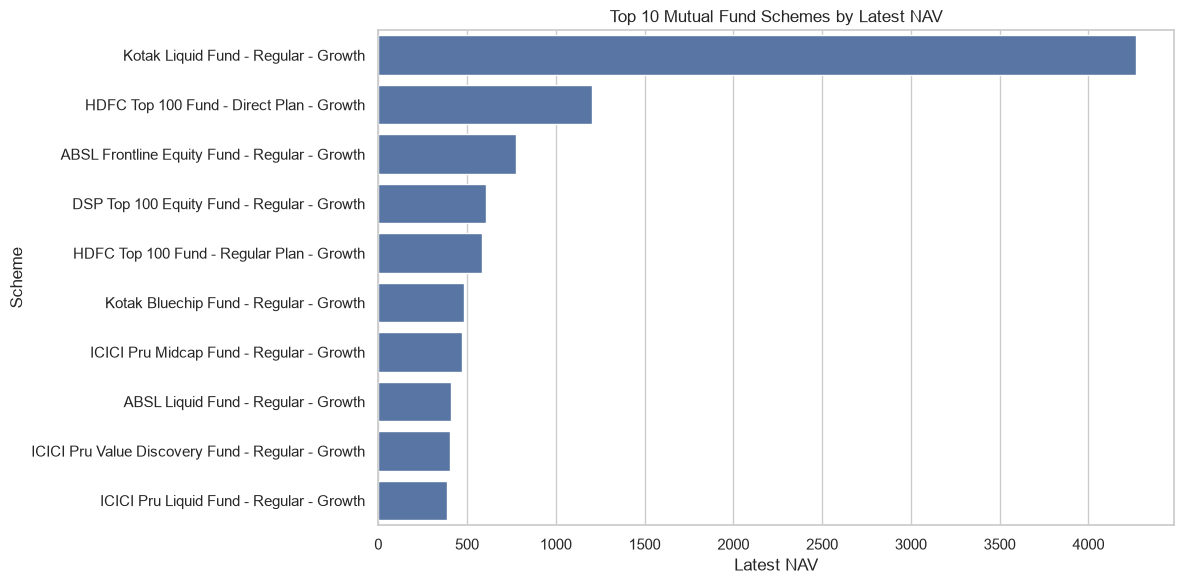

In [14]:
top10 = latest_nav.head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10,
    x="nav",
    y="scheme_name"
)

plt.title("Top 10 Mutual Fund Schemes by Latest NAV")
plt.xlabel("Latest NAV")
plt.ylabel("Scheme")

plt.tight_layout()

plt.savefig("../charts/nav/top10_latest_nav.png", dpi=300)

plt.show()

## Business Insight 2

- The top 10 schemes have significantly higher NAV values compared to the remaining schemes.
- These funds demonstrate consistent long-term appreciation and may represent mature or well-performing investment options.

# 2. Assets Under Management (AUM) Growth Analysis

### Objective

This analysis visualizes the Assets Under Management (AUM) of different mutual fund houses from **2022 to 2025**.

The objective is to compare the growth of fund houses over the years and identify the market leader.

In [15]:
print(aum.head())

print("\nColumns:")
print(aum.columns)

print("\nShape:")
print(aum.shape)

        date           fund_house  aum_lakh_crore  aum_crore  num_schemes
0 2022-03-31      SBI Mutual Fund            6.05     605000          186
1 2022-03-31  ICICI Prudential MF            4.65     465000          216
2 2022-03-31     HDFC Mutual Fund            4.35     435000          195
3 2022-03-31      Nippon India MF            2.70     270000          177
4 2022-03-31    Kotak Mahindra MF            2.70     270000          168

Columns:
Index(['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes'], dtype='str')

Shape:
(90, 5)


In [16]:
# Create a copy
aum_plot = aum.copy()

# Convert date column to datetime
aum_plot["date"] = pd.to_datetime(aum_plot["date"])

# Extract year
aum_plot["year"] = aum_plot["date"].dt.year

# Check data
aum_plot.head()

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes,year
0,2022-03-31,SBI Mutual Fund,6.05,605000,186,2022
1,2022-03-31,ICICI Prudential MF,4.65,465000,216,2022
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195,2022
3,2022-03-31,Nippon India MF,2.70,270000,177,2022
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168,2022


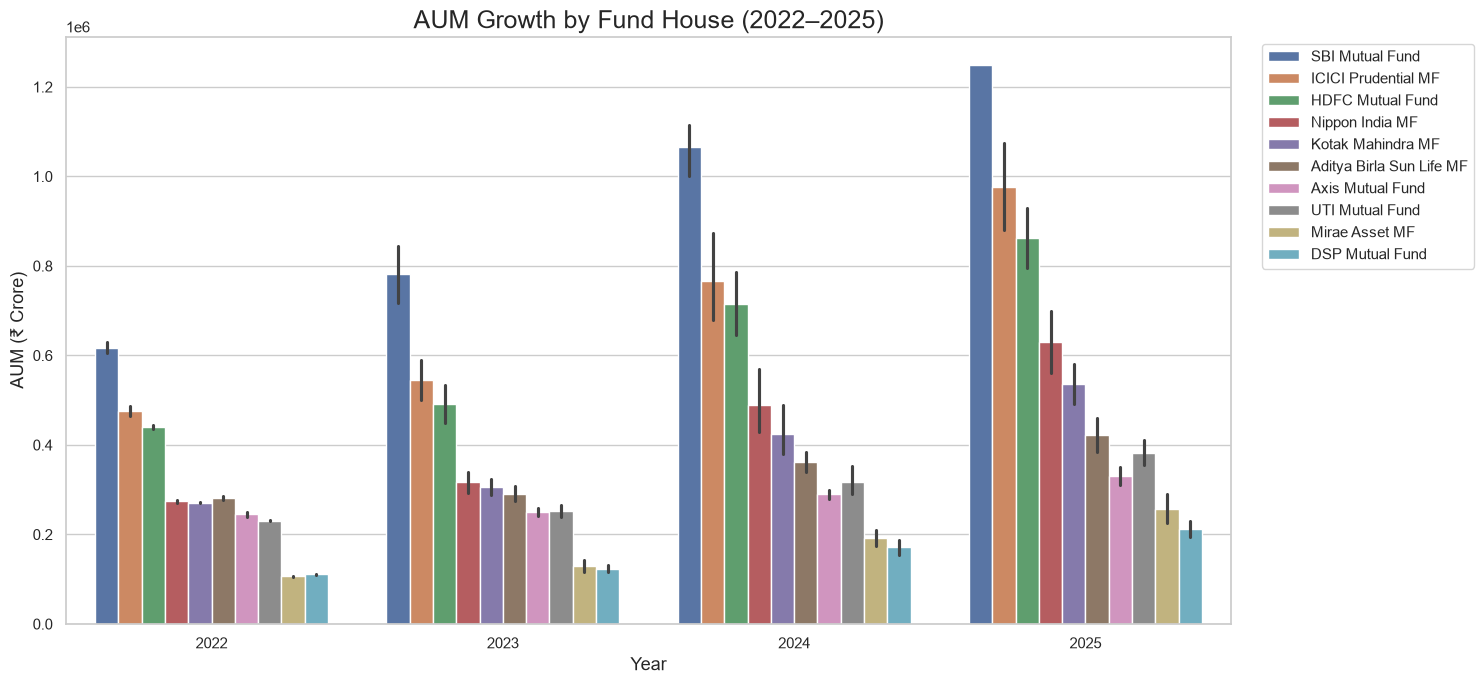

In [17]:
#Grouped bar chart
plt.figure(figsize=(15,7))

sns.barplot(
    data=aum_plot,
    x="year",
    y="aum_crore",
    hue="fund_house"
)

plt.title("AUM Growth by Fund House (2022–2025)", fontsize=18)

plt.xlabel("Year", fontsize=13)

plt.ylabel("AUM (₹ Crore)", fontsize=13)

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [18]:
#Highlight SBI
latest = aum_plot[aum_plot["year"] == 2025]

sbi = latest[
    latest["fund_house"] == "SBI Mutual Fund"
]

print(sbi)

         date       fund_house  aum_lakh_crore  aum_crore  num_schemes  year
70 2025-03-31  SBI Mutual Fund            12.5    1250000          186  2025
80 2025-12-31  SBI Mutual Fund            12.5    1250000          186  2025


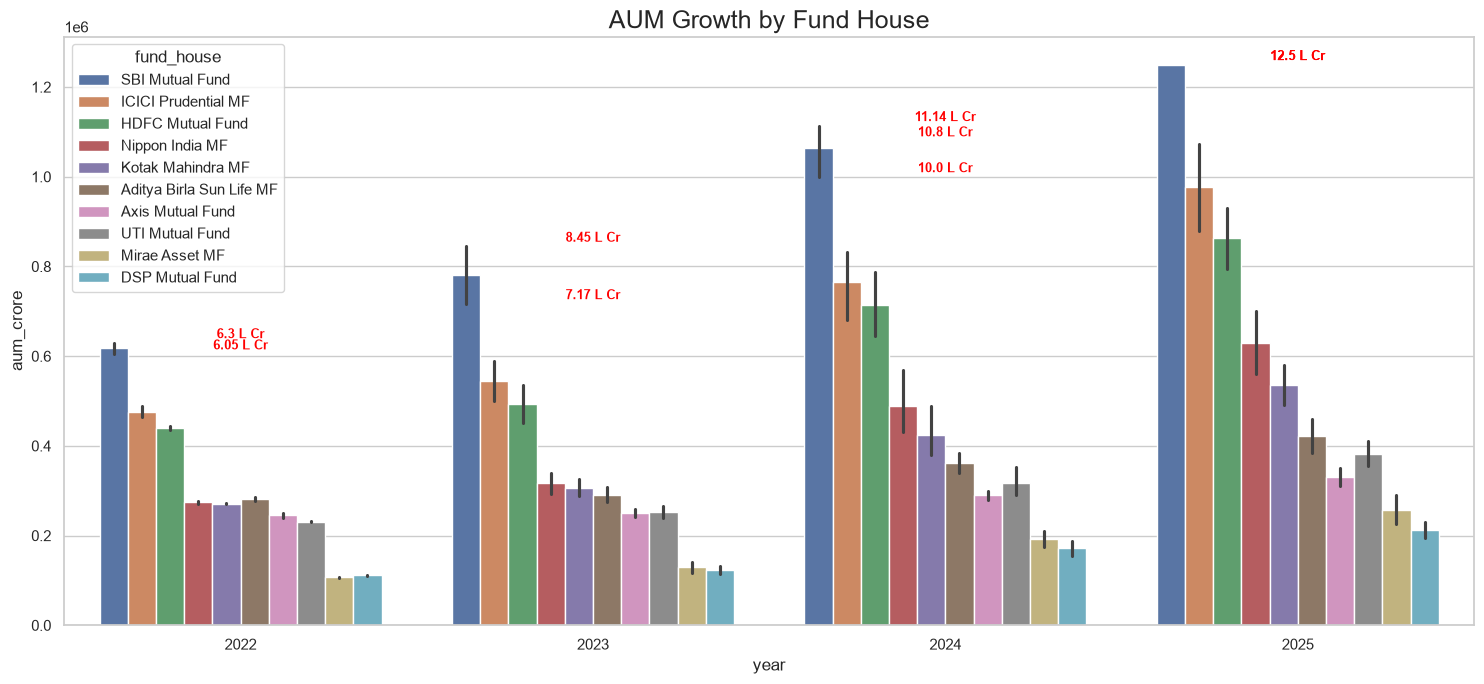

In [19]:
plt.figure(figsize=(15,7))

ax = sns.barplot(
    data=aum_plot,
    x="year",
    y="aum_crore",
    hue="fund_house"
)

# Annotate only SBI Mutual Fund
for i, row in aum_plot.iterrows():

    if row["fund_house"] == "SBI Mutual Fund":

        ax.text(
            x=row["year"]-2022,
            y=row["aum_crore"]+10000,
            s=f"{row['aum_lakh_crore']} L Cr",
            ha="center",
            fontsize=9,
            color="red",
            fontweight="bold"
        )

plt.title("AUM Growth by Fund House", fontsize=18)

plt.tight_layout()

plt.show()

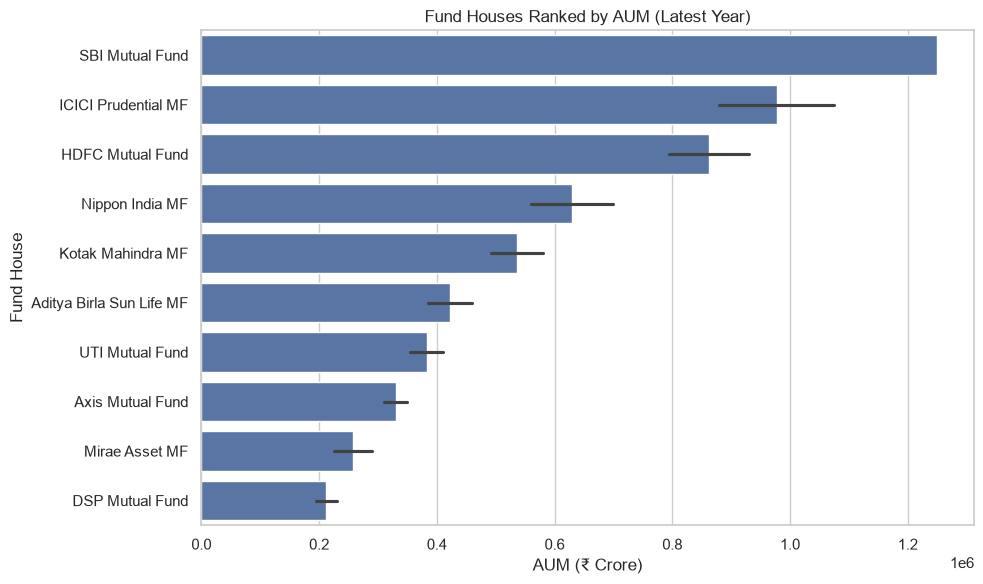

In [20]:
#Top 10 Fund Houses by AUM
top10 = (
    latest
    .sort_values("aum_crore", ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top10,
    x="aum_crore",
    y="fund_house"
)

plt.title("Fund Houses Ranked by AUM (Latest Year)")

plt.xlabel("AUM (₹ Crore)")

plt.ylabel("Fund House")

plt.tight_layout()

plt.show()

In [22]:
from pathlib import Path

Path("../charts/aum").mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    "../charts/aum/top_fund_houses.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Business Insight 3

- SBI Mutual Fund consistently remained the market leader in Assets Under Management (AUM).
- All major fund houses witnessed positive AUM growth from 2022 to 2025.
- Increasing AUM reflects growing investor confidence and expansion of the mutual fund industry.

# 3. SIP Inflow Trend Analysis

### Objective

Systematic Investment Plans (SIPs) are one of the most important indicators of retail investor participation.

This section analyzes the monthly SIP inflows from January 2022 to December 2025 to identify growth trends and major milestones.

In [23]:
print(sip.head())

print("\nColumns:")
print(sip.columns)

print("\nShape:")
print(sip.shape)

       month  sip_inflow_crore  active_sip_accounts_crore  \
0 2022-01-01             11517                       4.91   
1 2022-02-01             11438                       4.93   
2 2022-03-01             12328                       5.09   
3 2022-04-01             11863                       5.48   
4 2022-05-01             12286                       5.55   

   new_sip_accounts_lakh  sip_aum_lakh_crore  yoy_growth_pct  
0                   9.10                4.80             NaN  
1                   8.20                4.85             NaN  
2                  10.50                5.01             NaN  
3                   9.52                5.12             NaN  
4                   8.10                5.15             NaN  

Columns:
Index(['month', 'sip_inflow_crore', 'active_sip_accounts_crore',
       'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct'],
      dtype='str')

Shape:
(48, 6)


# 3. Monthly SIP Inflow Analysis

### Objective

This section analyzes monthly SIP inflows from January 2022 to December 2025.

The analysis focuses on:

- Monthly SIP Growth
- Highest SIP Collection
- Growth in Active SIP Accounts
- SIP AUM Growth
- Business Insights

In [24]:
sip_plot = sip.copy()

sip_plot["month"] = pd.to_datetime(sip_plot["month"])

sip_plot.head()

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01-01,11517,4.91,9.10,4.80,NaN
1,2022-02-01,11438,4.93,8.20,4.85,NaN
2,2022-03-01,12328,5.09,10.50,5.01,NaN
3,2022-04-01,11863,5.48,9.52,5.12,NaN
4,2022-05-01,12286,5.55,8.10,5.15,NaN


In [25]:
print("SIP Statistics")

print("-"*40)

print("Highest SIP Inflow : ₹",
      sip_plot["sip_inflow_crore"].max(),"Cr")

print("Lowest SIP Inflow : ₹",
      sip_plot["sip_inflow_crore"].min(),"Cr")

print("Average SIP Inflow : ₹",
      round(sip_plot["sip_inflow_crore"].mean(),2),"Cr")

print("Highest Active SIP Accounts :",
      sip_plot["active_sip_accounts_crore"].max(),"Crore")

print("Highest SIP AUM :",
      sip_plot["sip_aum_lakh_crore"].max(),"Lakh Crore")

SIP Statistics
----------------------------------------
Highest SIP Inflow : ₹ 31002 Cr
Lowest SIP Inflow : ₹ 11438 Cr
Average SIP Inflow : ₹ 19577.52 Cr
Highest Active SIP Accounts : 9.35 Crore
Highest SIP AUM : 15.9 Lakh Crore


In [26]:
fig = px.line(
    sip_plot,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (2022–2025)",
    labels={
        "month":"Month",
        "sip_inflow_crore":"SIP Inflow (₹ Crore)"
    }
)

fig.update_layout(

    template="plotly_white",

    title_x=0.5,

    height=600
)

fig.show()

In [27]:
highest = sip_plot.loc[
    sip_plot["sip_inflow_crore"].idxmax()
]

highest

month                        2025-12-01 00:00:00
sip_inflow_crore                           31002
active_sip_accounts_crore                   9.35
new_sip_accounts_lakh                        9.8
sip_aum_lakh_crore                          15.9
yoy_growth_pct                             17.17
Name: 47, dtype: object

In [28]:
fig = px.line(
    sip_plot,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflow Trend (2022–2025)"
)

fig.add_annotation(

    x=highest["month"],

    y=highest["sip_inflow_crore"],

    text=f"Highest SIP<br>₹{highest['sip_inflow_crore']} Cr",

    showarrow=True,

    arrowhead=2,

    bgcolor="yellow"
)

fig.show()

In [29]:
from pathlib import Path

Path("../charts/sip").mkdir(
    parents=True,
    exist_ok=True
)

fig.write_html(
    "../charts/sip/monthly_sip_trend.html"
)

print("Chart saved successfully.")

Chart saved successfully.


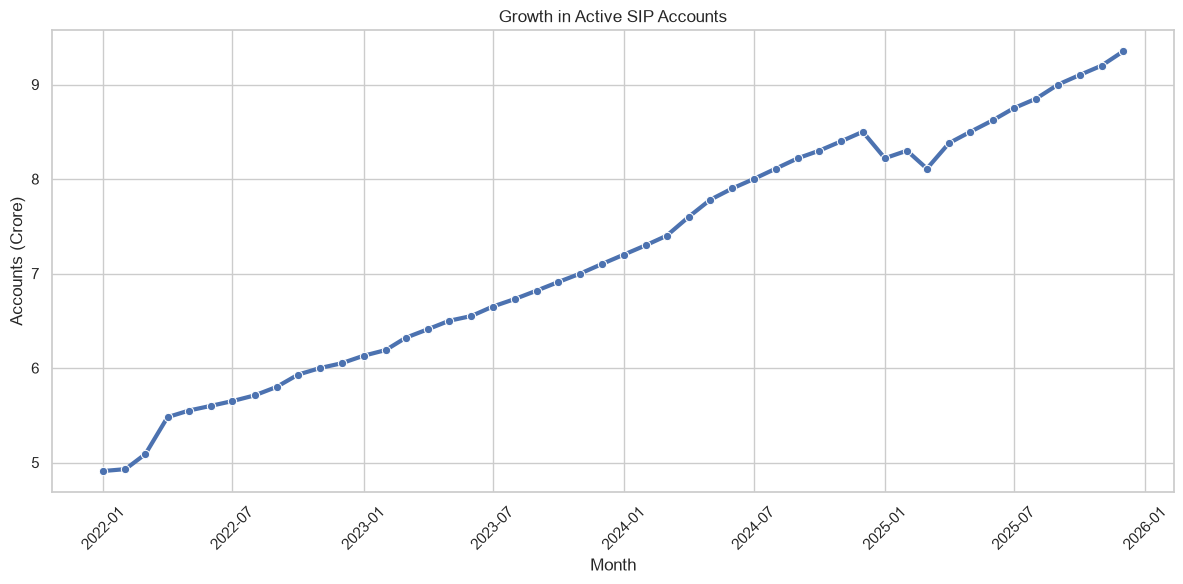

In [30]:
plt.figure(figsize=(12,6))

sns.lineplot(

    data=sip_plot,

    x="month",

    y="active_sip_accounts_crore",

    marker="o",

    linewidth=3

)

plt.title("Growth in Active SIP Accounts")

plt.xlabel("Month")

plt.ylabel("Accounts (Crore)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

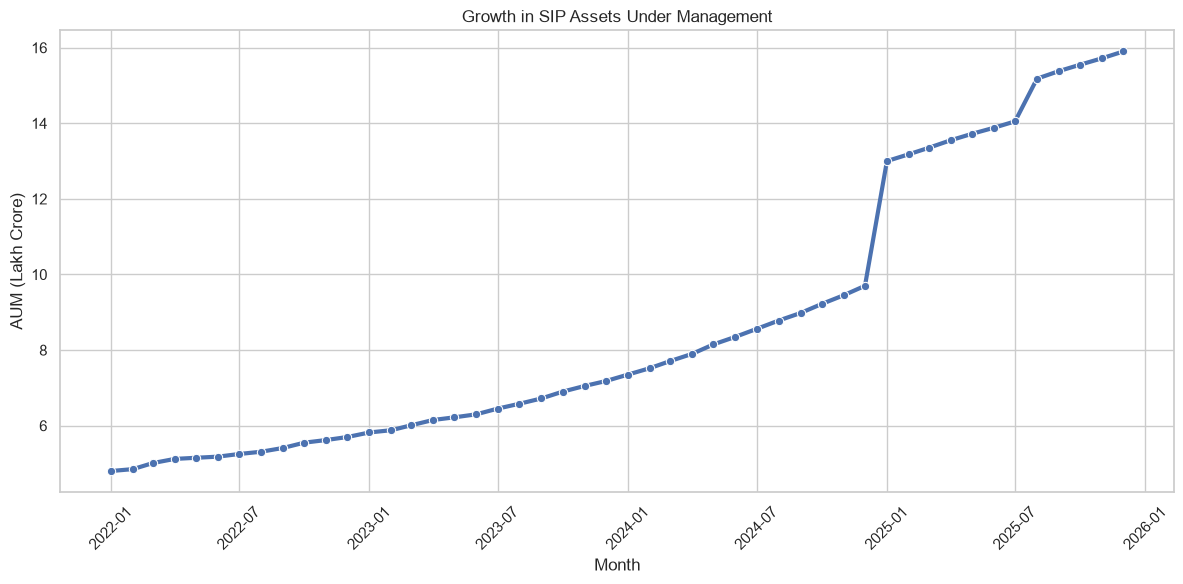

In [31]:
plt.figure(figsize=(12,6))

sns.lineplot(

    data=sip_plot,

    x="month",

    y="sip_aum_lakh_crore",

    marker="o",

    linewidth=3

)

plt.title("Growth in SIP Assets Under Management")

plt.xlabel("Month")

plt.ylabel("AUM (Lakh Crore)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

## Business Insight 4

- Monthly SIP inflows show a consistent upward trend during the analysis period.
- The highest SIP inflow was recorded towards the end of the study period, reflecting increasing investor confidence.
- Active SIP accounts have steadily increased, indicating growing participation from retail investors.
- SIP Assets Under Management (AUM) also witnessed sustained growth, highlighting the long-term investment preference of investors.

# 4. Category-wise Mutual Fund Inflow Analysis

### Objective

This section analyzes the monthly inflows across different mutual fund categories.

The objective is to identify:

- Categories receiving the highest investments
- Seasonal investment patterns
- Category-wise investor preference
- Overall inflow trends

In [32]:
print(category.head())

print("\nColumns:")
print(category.columns)

print("\nShape:")
print(category.shape)

       month         category  net_inflow_crore
0 2024-04-01        Large Cap            2413.0
1 2024-04-01          Mid Cap            3897.0
2 2024-04-01        Small Cap            3533.0
3 2024-04-01        Flexi Cap            4947.0
4 2024-04-01  Large & Mid Cap            4214.0

Columns:
Index(['month', 'category', 'net_inflow_crore'], dtype='str')

Shape:
(144, 3)


In [33]:
category_plot = category.copy()

category_plot["month"] = pd.to_datetime(category_plot["month"])

category_plot["month_name"] = category_plot["month"].dt.strftime("%b-%Y")

category_plot.head()

,month,category,net_inflow_crore,month_name
0,2024-04-01,Large Cap,2413.0,Apr-2024
1,2024-04-01,Mid Cap,3897.0,Apr-2024
2,2024-04-01,Small Cap,3533.0,Apr-2024
3,2024-04-01,Flexi Cap,4947.0,Apr-2024
4,2024-04-01,Large & Mid Cap,4214.0,Apr-2024


In [34]:
print("Category Statistics")

print("-"*50)

print("Total Categories :",
      category_plot["category"].nunique())

print("Highest Net Inflow : ₹",
      category_plot["net_inflow_crore"].max(),"Cr")

print("Lowest Net Inflow : ₹",
      category_plot["net_inflow_crore"].min(),"Cr")

print("Average Monthly Inflow : ₹",
      round(category_plot["net_inflow_crore"].mean(),2),"Cr")

Category Statistics
--------------------------------------------------
Total Categories : 12
Highest Net Inflow : ₹ 41952.0 Cr
Lowest Net Inflow : ₹ 437.0 Cr
Average Monthly Inflow : ₹ 6473.88 Cr


In [35]:
heatmap_data = category_plot.pivot_table(
    index="category",
    columns="month_name",
    values="net_inflow_crore"
)

heatmap_data

month_name,Apr-2024,Aug-2024,Dec-2024,Feb-2025,Jan-2025,Jul-2024,Jun-2024,Mar-2025,May-2024,Nov-2024,Oct-2024,Sep-2024
category,,,,,,,,,,,,
ELSS,466.0,499.0,521.0,437.0,516.0,471.0,472.0,500.0,553.0,571.0,537.0,537.0
Flexi Cap,4947.0,5562.0,4654.0,6068.0,5603.0,4869.0,4478.0,4767.0,5529.0,6111.0,6004.0,5397.0
Gilt,784.0,952.0,831.0,942.0,744.0,959.0,864.0,956.0,836.0,704.0,898.0,925.0
Hybrid,2955.0,3684.0,3538.0,3360.0,2967.0,3291.0,3163.0,2830.0,3487.0,3264.0,3314.0,3015.0
Large & Mid Cap,4214.0,5411.0,4878.0,5524.0,4816.0,5023.0,4610.0,4243.0,4368.0,5556.0,4581.0,4528.0
Large Cap,2413.0,1940.0,1923.0,1925.0,2025.0,2574.0,2519.0,2234.0,2076.0,1870.0,2255.0,1879.0
Liquid,37537.0,41952.0,34933.0,32374.0,33892.0,34643.0,40486.0,38681.0,41872.0,40506.0,39091.0,35308.0
Mid Cap,3897.0,3899.0,5023.0,4819.0,4316.0,4548.0,5047.0,5061.0,5300.0,4336.0,4106.0,4960.0
Sectoral/Thematic,8052.0,8360.0,9820.0,9215.0,7893.0,9896.0,10030.0,8614.0,8354.0,7397.0,7680.0,8518.0


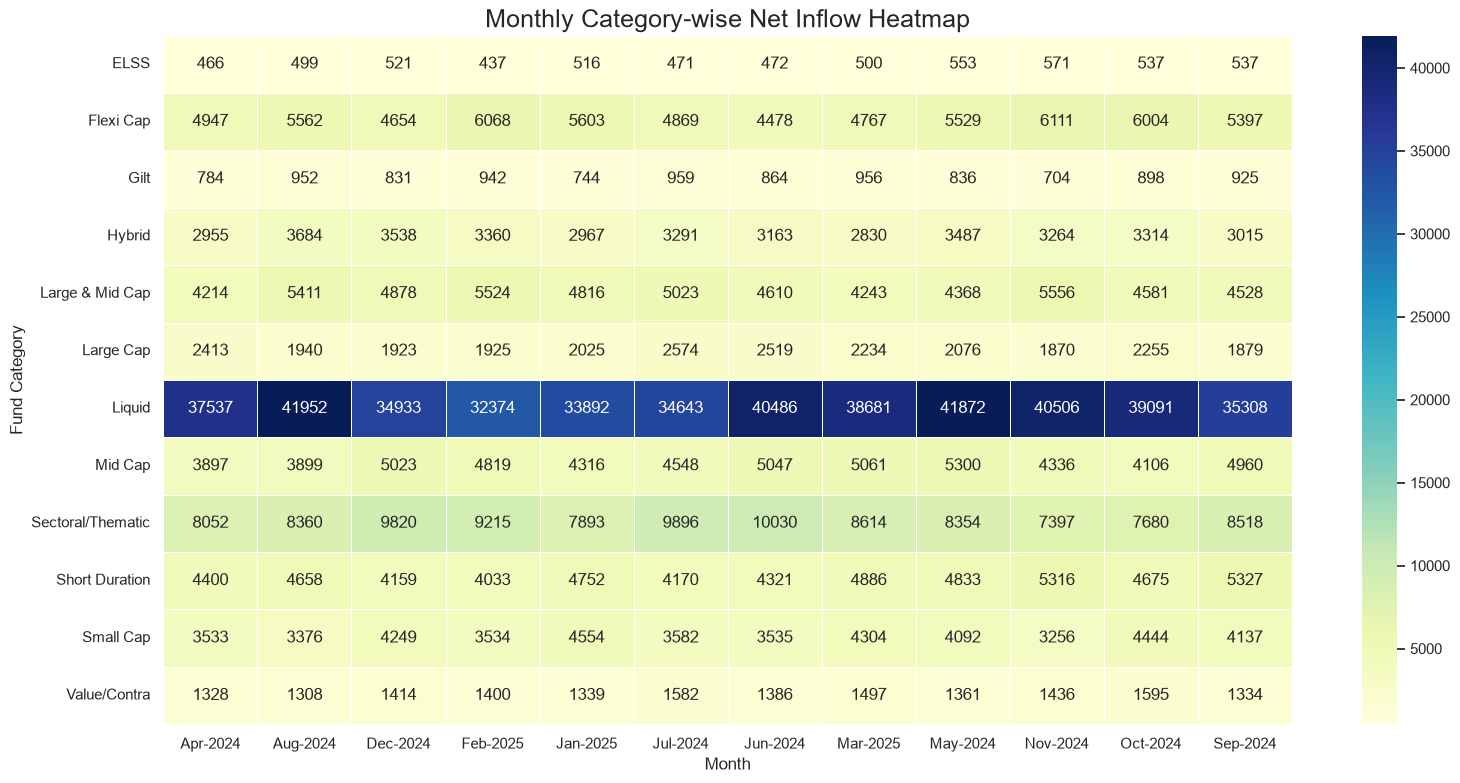

In [36]:
plt.figure(figsize=(16,8))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=0.5
)

plt.title(
    "Monthly Category-wise Net Inflow Heatmap",
    fontsize=18
)

plt.xlabel("Month")

plt.ylabel("Fund Category")

plt.tight_layout()

plt.show()

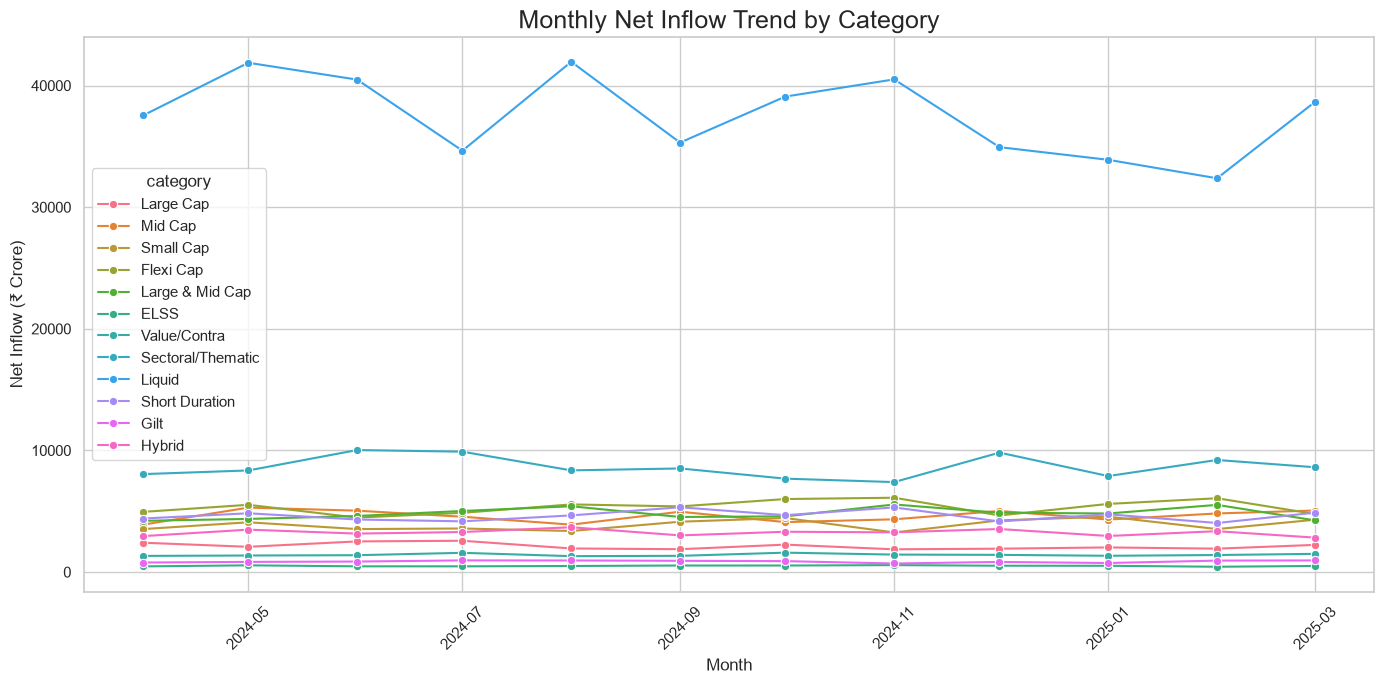

In [37]:
plt.figure(figsize=(14,7))

sns.lineplot(
    data=category_plot,
    x="month",
    y="net_inflow_crore",
    hue="category",
    marker="o"
)

plt.title(
    "Monthly Net Inflow Trend by Category",
    fontsize=18
)

plt.xlabel("Month")

plt.ylabel("Net Inflow (₹ Crore)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [38]:
top_categories = (
    category_plot
    .groupby("category")["net_inflow_crore"]
    .sum()
    .reset_index()
    .sort_values(
        "net_inflow_crore",
        ascending=False
    )
)

top_categories

,category,net_inflow_crore
6,Liquid,451275.0
8,Sectoral/Thematic,103829.0
1,Flexi Cap,63989.0
4,Large & Mid Cap,57752.0
9,Short Duration,55530.0
7,Mid Cap,55312.0
10,Small Cap,46596.0
3,Hybrid,38868.0
5,Large Cap,25633.0
11,Value/Contra,16980.0


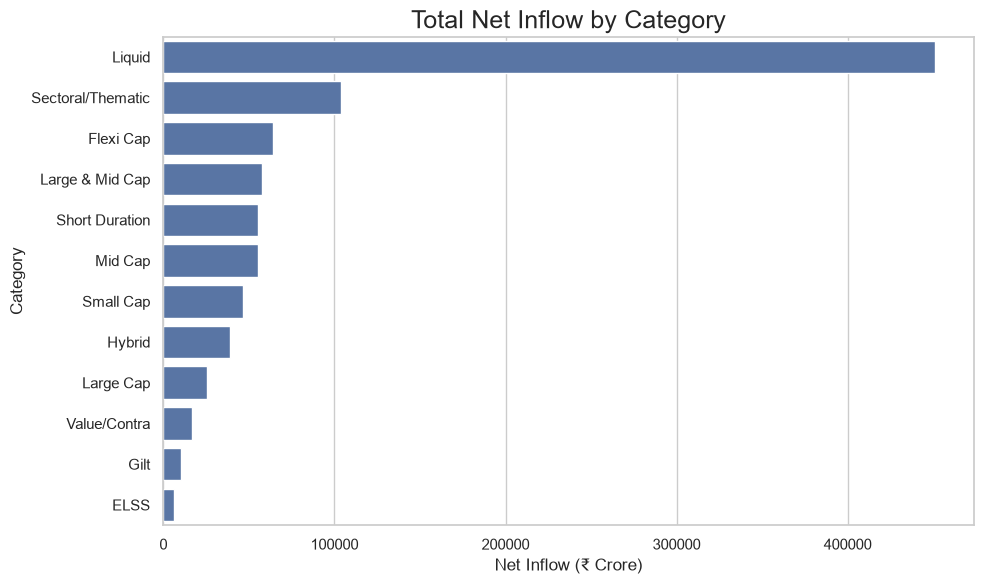

In [39]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_categories,
    x="net_inflow_crore",
    y="category"
)

plt.title(
    "Total Net Inflow by Category",
    fontsize=18
)

plt.xlabel("Net Inflow (₹ Crore)")

plt.ylabel("Category")

plt.tight_layout()

plt.show()

In [40]:
from pathlib import Path

Path("../charts/category").mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    "../charts/category/category_inflow.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Business Insight 5

- Flexi Cap and Large & Mid Cap funds consistently attracted strong investor inflows.
- Category-wise investment trends indicate that investors preferred diversified equity-oriented funds during the study period.
- The heatmap highlights clear monthly variations in investment behaviour, reflecting changing market sentiment.

In [41]:
highest = category_plot.loc[
    category_plot["net_inflow_crore"].idxmax()
]

print(highest)

month               2024-08-01 00:00:00
category                         Liquid
net_inflow_crore                41952.0
month_name                     Aug-2024
Name: 56, dtype: object


In [42]:
print(transactions.head())

print("\nColumns:")
print(transactions.columns)

print("\nShape:")
print(transactions.shape)

  investor_id transaction_date  amfi_code transaction_type  amount_inr  \
0   INV003054       2024-01-01     119092              SIP        1834   
1   INV002952       2024-01-01     148567       Redemption      392882   
2   INV003420       2024-01-01     118636              SIP         912   
3   INV003436       2024-01-01     118634              SIP        1102   
4   INV004691       2024-01-01     119094          Lumpsum        8682   

         state       city city_tier age_group  gender  annual_income_lakh  \
0    Telangana  Hyderabad       T30       56+  Female                77.1   
1       Punjab   Amritsar       B30     18-25    Male                 7.1   
2      Haryana  Faridabad       B30     36-45    Male                47.2   
3  Maharashtra     Mumbai       T30     36-45  Female                54.4   
4        Delhi      Noida       T30     26-35    Male                14.5   

  payment_mode kyc_status  
0          UPI   Verified  
1       Cheque   Verified  
2      M

# 5. Investor Demographics Analysis

### Objective

This section analyzes investor demographics to understand the characteristics of mutual fund investors.

The analysis includes:

- Age Group Distribution
- Gender Distribution
- Investment Amount by Age Group
- Additional demographic insights

In [43]:
print("Total Investors :", transactions["investor_id"].nunique())

print("Age Groups :")
print(transactions["age_group"].unique())

print("\nGender :")
print(transactions["gender"].unique())

Total Investors : 5000
Age Groups :
<StringArray>
['56+', '18-25', '36-45', '26-35', '46-55']
Length: 5, dtype: str

Gender :
<StringArray>
['Female', 'Male']
Length: 2, dtype: str


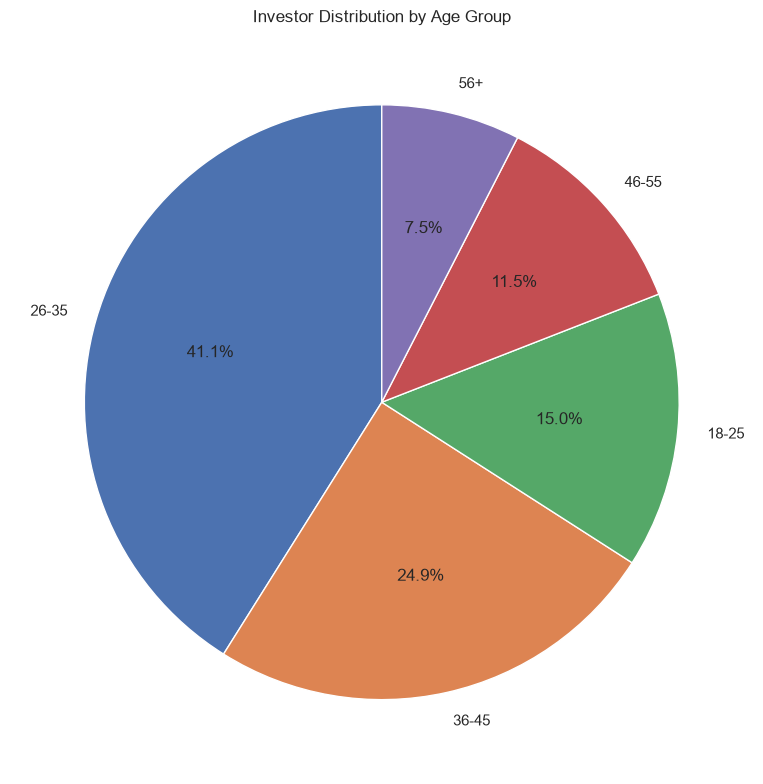

In [44]:
plt.figure(figsize=(8,8))

age_counts = transactions["age_group"].value_counts()

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Investor Distribution by Age Group")

plt.tight_layout()

plt.show()

### Business Insight 6

- The majority of investors belong to the working-age population.
- Younger investors are increasingly participating in mutual fund investments through SIPs.

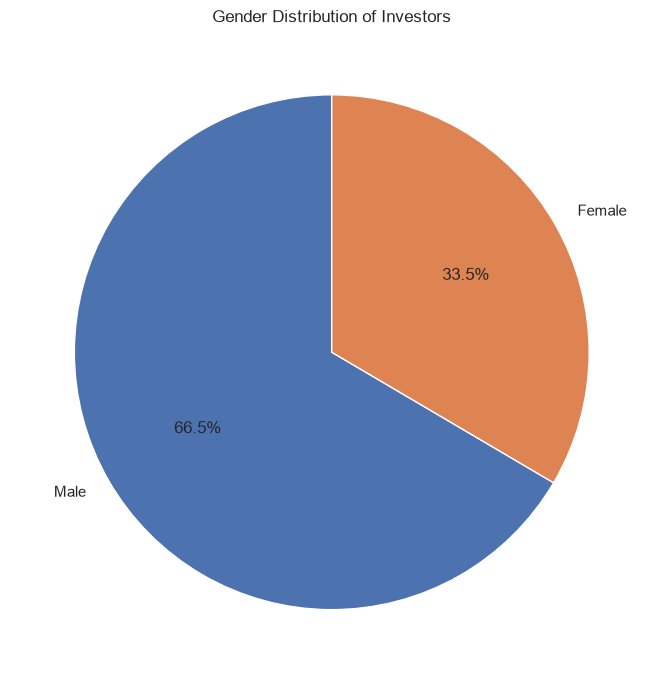

In [45]:
plt.figure(figsize=(7,7))

gender_counts = transactions["gender"].value_counts()

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution of Investors")

plt.tight_layout()

plt.show()

### Business Insight 7

- The gender distribution highlights the participation of both male and female investors.
- Increasing diversity indicates wider adoption of mutual fund investments.

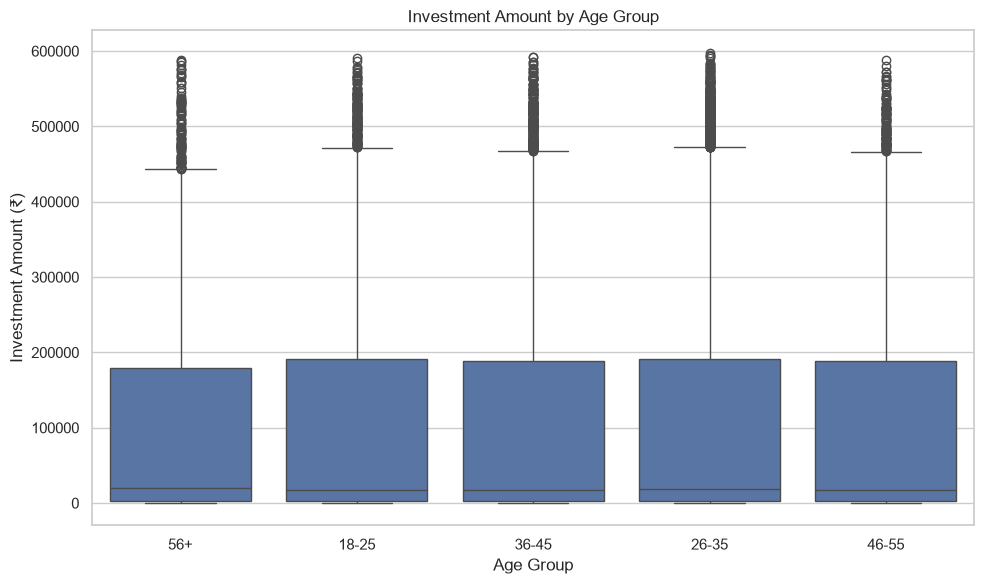

In [46]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=transactions,
    x="age_group",
    y="amount_inr"
)

plt.title("Investment Amount by Age Group")

plt.xlabel("Age Group")

plt.ylabel("Investment Amount (₹)")

plt.tight_layout()

plt.show()

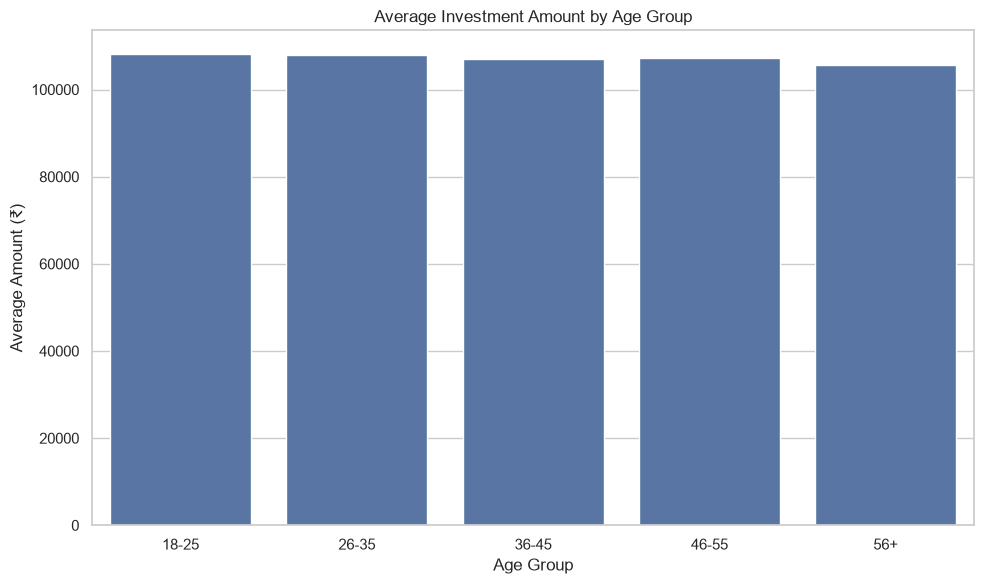

In [47]:
age_avg = (
    transactions
    .groupby("age_group")["amount_inr"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=age_avg,
    x="age_group",
    y="amount_inr"
)

plt.title("Average Investment Amount by Age Group")

plt.xlabel("Age Group")

plt.ylabel("Average Amount (₹)")

plt.tight_layout()

plt.show()

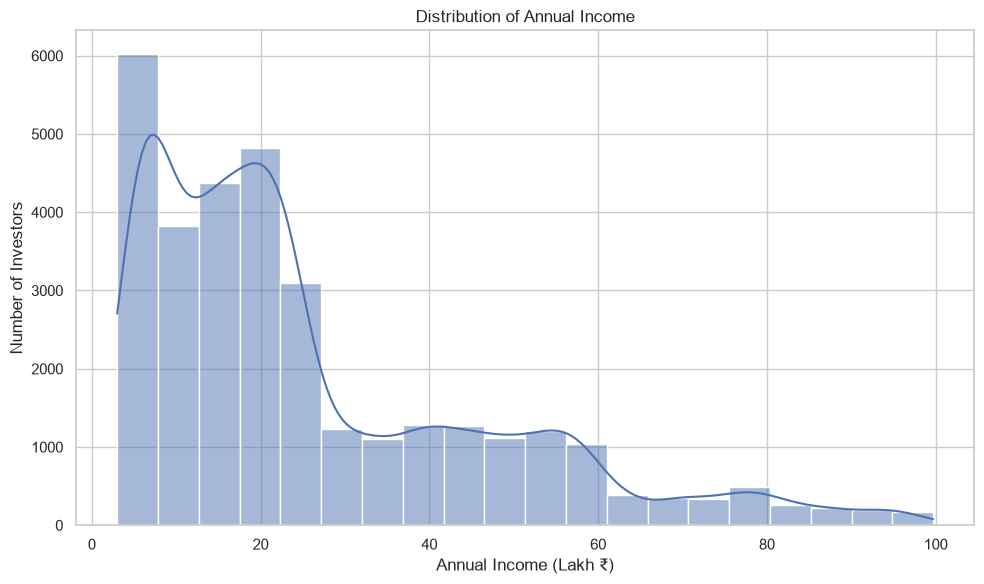

In [48]:
plt.figure(figsize=(10,6))

sns.histplot(
    transactions["annual_income_lakh"],
    bins=20,
    kde=True
)

plt.title("Distribution of Annual Income")

plt.xlabel("Annual Income (Lakh ₹)")

plt.ylabel("Number of Investors")

plt.tight_layout()

plt.show()

## Business Insight 8

- Investors with higher annual income generally contribute larger investment amounts.
- The majority of investors belong to the middle-income segment, indicating strong retail participation in mutual funds.

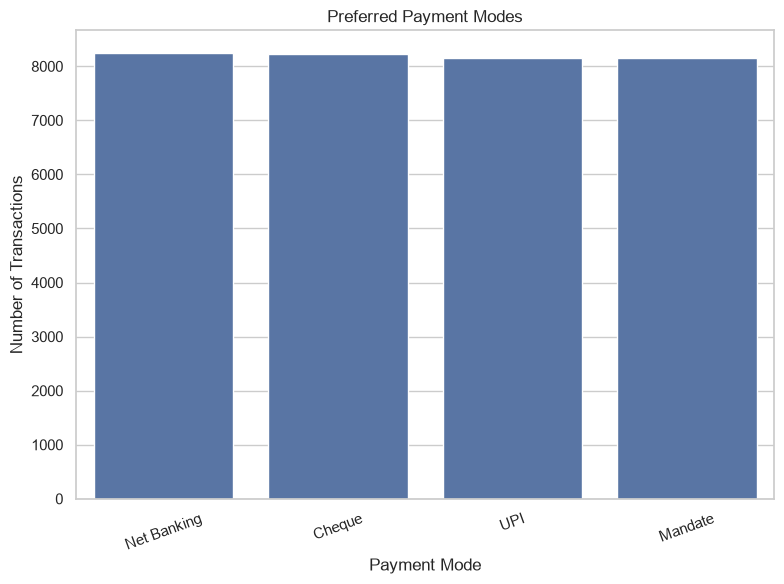

In [49]:
plt.figure(figsize=(8,6))

payment = transactions["payment_mode"].value_counts()

sns.barplot(
    x=payment.index,
    y=payment.values
)

plt.title("Preferred Payment Modes")

plt.xlabel("Payment Mode")

plt.ylabel("Number of Transactions")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

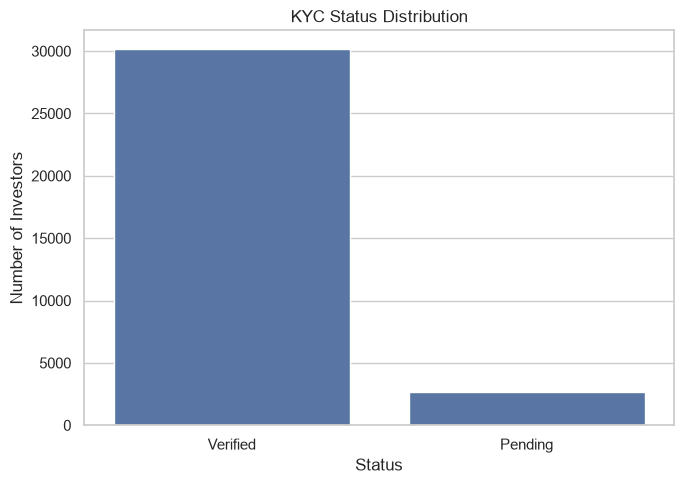

In [50]:
plt.figure(figsize=(7,5))

kyc = transactions["kyc_status"].value_counts()

sns.barplot(
    x=kyc.index,
    y=kyc.values
)

plt.title("KYC Status Distribution")

plt.xlabel("Status")

plt.ylabel("Number of Investors")

plt.tight_layout()

plt.show()

# 6. Geographic Distribution Analysis

## Objective

This section analyzes the geographical distribution of mutual fund investments across different states and cities.

The analysis includes:

- State-wise Investment Distribution
- Top 10 Cities by Investment
- T30 vs B30 City Tier Analysis
- Business Insights

In [51]:
print("Total States :", transactions["state"].nunique())

print("Total Cities :", transactions["city"].nunique())

print("\nCity Tiers :")
print(transactions["city_tier"].unique())

Total States : 12
Total Cities : 24

City Tiers :
<StringArray>
['T30', 'B30']
Length: 2, dtype: str


In [52]:
state_amount = (
    transactions
    .groupby("state")["amount_inr"]
    .sum()
    .reset_index()
    .sort_values("amount_inr", ascending=False)
)

state_amount.head()

,state,amount_inr
6,Punjab,315780459
8,Tamil Nadu,315177237
4,Madhya Pradesh,308312493
7,Rajasthan,298645822
1,Gujarat,298358940


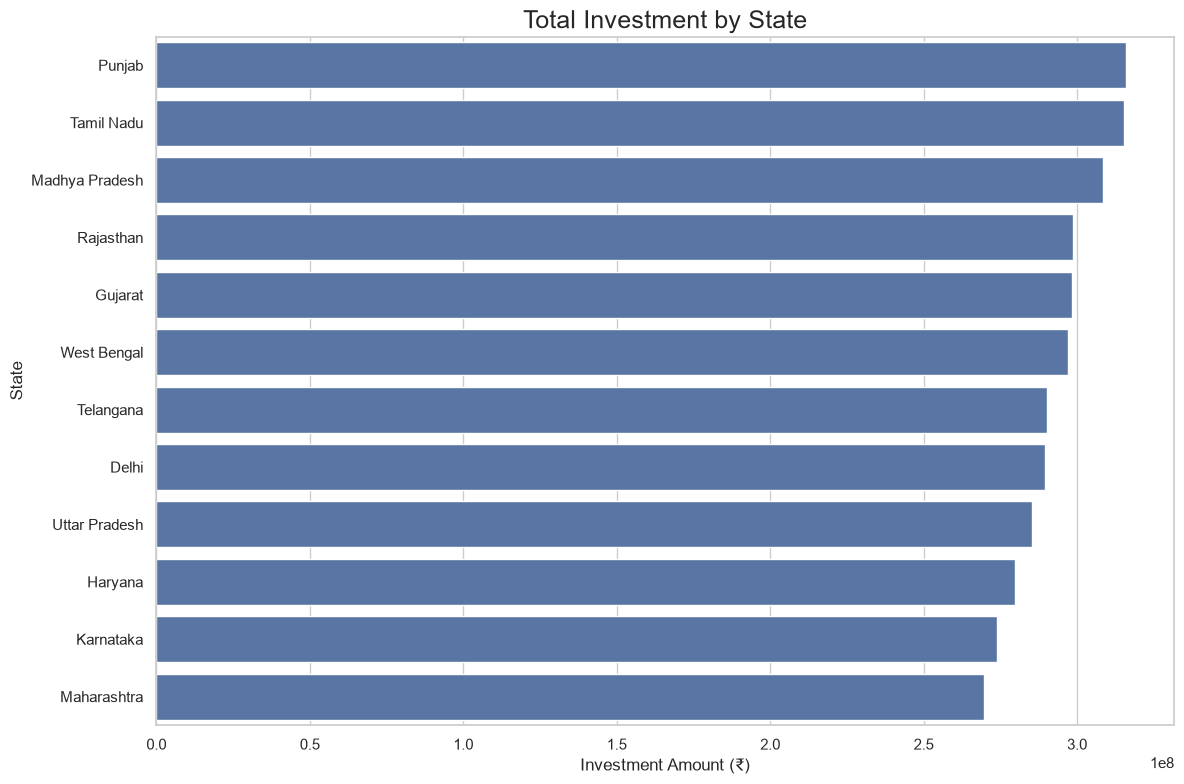

In [53]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=state_amount,
    y="state",
    x="amount_inr"
)

plt.title(
    "Total Investment by State",
    fontsize=18
)

plt.xlabel("Investment Amount (₹)")

plt.ylabel("State")

plt.tight_layout()

plt.show()

## Business Insight 9

- Metro states contribute the highest investment volume.
- Higher urbanization and financial awareness are strongly associated with greater mutual fund participation.

In [54]:
city_amount = (
    transactions
    .groupby("city")["amount_inr"]
    .sum()
    .reset_index()
    .sort_values(
        "amount_inr",
        ascending=False
    )
)

city_amount.head(10)

,city,amount_inr
14,Kolkata,297182514
10,Hyderabad,290219284
9,Gurugram,223778908
7,Coimbatore,170345165
4,Bhopal,165606495
1,Ahmedabad,160916535
2,Amritsar,159315652
5,Chandigarh,156464807
12,Jaipur,153768697
8,Faridabad,148078011


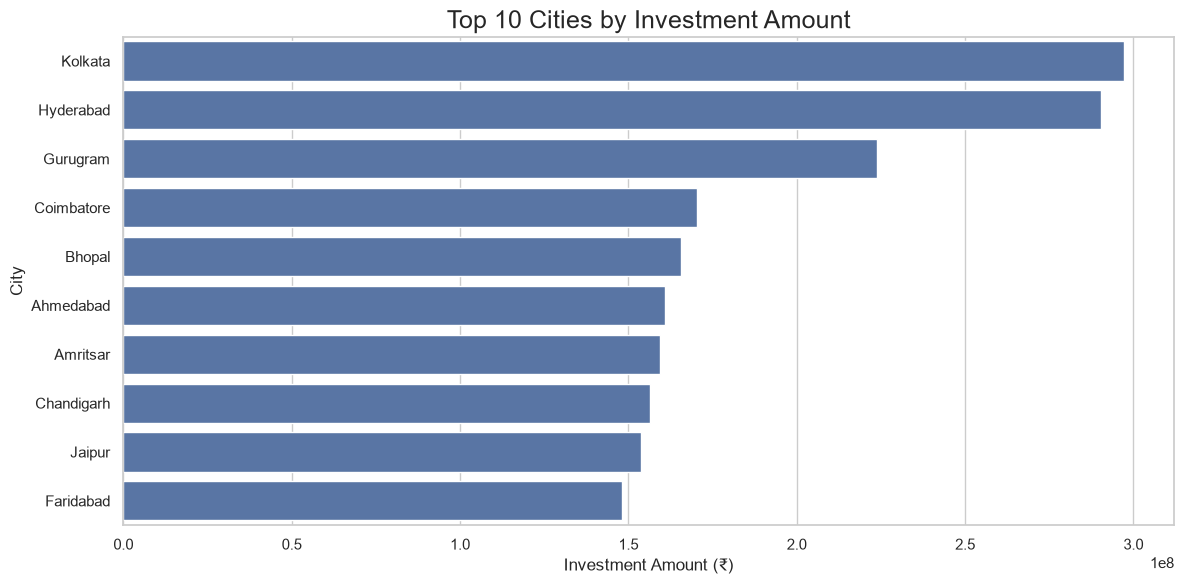

In [55]:
top10_city = city_amount.head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10_city,
    x="amount_inr",
    y="city"
)

plt.title(
    "Top 10 Cities by Investment Amount",
    fontsize=18
)

plt.xlabel("Investment Amount (₹)")

plt.ylabel("City")

plt.tight_layout()

plt.show()

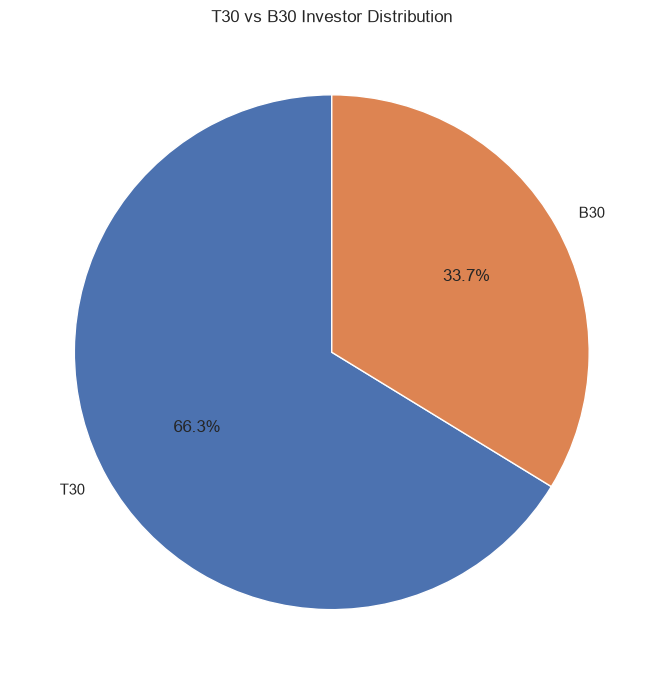

In [56]:
tier = transactions["city_tier"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    tier,
    labels=tier.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("T30 vs B30 Investor Distribution")

plt.tight_layout()

plt.show()

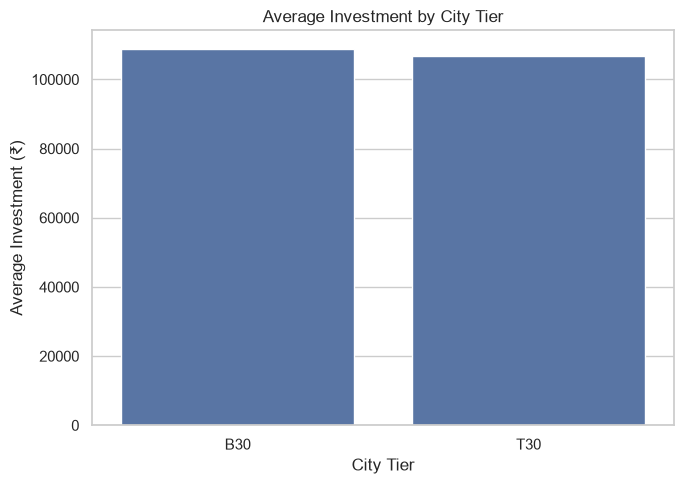

In [57]:
tier_avg = (
    transactions
    .groupby("city_tier")["amount_inr"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7,5))

sns.barplot(
    data=tier_avg,
    x="city_tier",
    y="amount_inr"
)

plt.title("Average Investment by City Tier")

plt.xlabel("City Tier")

plt.ylabel("Average Investment (₹)")

plt.tight_layout()

plt.show()

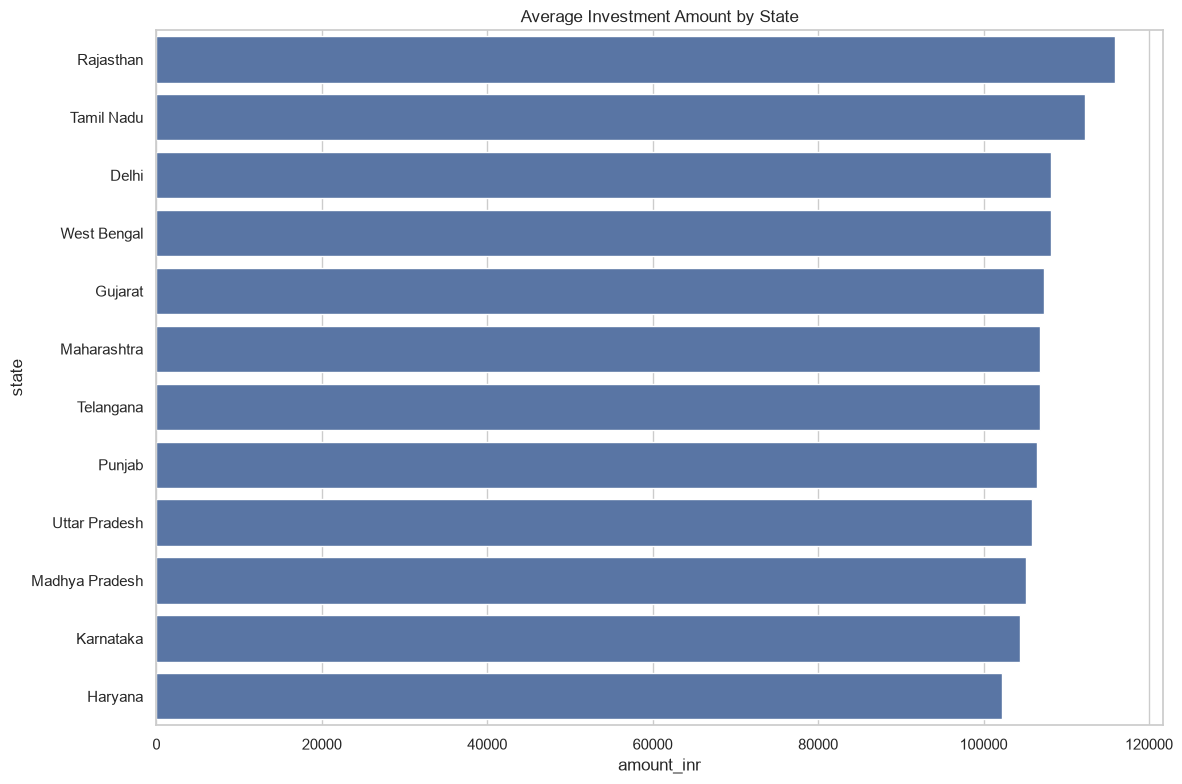

In [58]:
avg_state = (
    transactions
    .groupby("state")["amount_inr"]
    .mean()
    .reset_index()
    .sort_values(
        "amount_inr",
        ascending=False
    )
)

plt.figure(figsize=(12,8))

sns.barplot(
    data=avg_state,
    y="state",
    x="amount_inr"
)

plt.title("Average Investment Amount by State")

plt.tight_layout()

plt.show()

In [59]:
from pathlib import Path

Path("../charts/geography").mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    "../charts/geography/state_investment.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Business Insight 10

- T30 cities account for a significant share of mutual fund investments due to stronger financial infrastructure and investor awareness.
- B30 cities also contribute meaningfully, highlighting the growing penetration of mutual funds beyond major metropolitan regions.
- Geographic diversification of investments suggests expanding retail participation across India.

# 7. Folio Growth Analysis

## Objective

This analysis visualizes the growth of mutual fund folios over time.

An increase in folio count indicates growing investor participation and expansion of the mutual fund industry.

In [60]:
print(folio.head())

print("\nColumns:")
print(folio.columns)

print("\nShape:")
print(folio.shape)

       month  total_folios_crore  equity_folios_crore  debt_folios_crore  \
0 2022-01-01               13.26                 9.28               1.86   
1 2022-04-01               13.91                 9.74               1.95   
2 2022-07-01               13.85                 9.69               1.94   
3 2022-10-01               14.12                 9.88               1.98   
4 2023-01-01               14.81                10.37               2.07   

   hybrid_folios_crore  others_folios_crore  
0                 0.80                 1.33  
1                 0.83                 1.39  
2                 0.83                 1.38  
3                 0.85                 1.41  
4                 0.89                 1.48  

Columns:
Index(['month', 'total_folios_crore', 'equity_folios_crore',
       'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore'],
      dtype='str')

Shape:
(21, 6)


# 7. Folio Growth Analysis

## Objective

This section analyzes the growth of mutual fund folios from 2022 to 2026.

Increasing folio counts indicate growing investor participation in the mutual fund industry.

In [61]:
folio_plot = folio.copy()

folio_plot["month"] = pd.to_datetime(folio_plot["month"])

folio_plot.head()

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01-01,13.26,9.28,1.86,0.80,1.33
1,2022-04-01,13.91,9.74,1.95,0.83,1.39
2,2022-07-01,13.85,9.69,1.94,0.83,1.38
3,2022-10-01,14.12,9.88,1.98,0.85,1.41
4,2023-01-01,14.81,10.37,2.07,0.89,1.48


In [62]:
print("Folio Statistics")

print("-"*40)

print("Starting Folios :",
      folio_plot["total_folios_crore"].iloc[0],
      "Crore")

print("Latest Folios :",
      folio_plot["total_folios_crore"].iloc[-1],
      "Crore")

print("Growth :",
      round(
          folio_plot["total_folios_crore"].iloc[-1]
          -
          folio_plot["total_folios_crore"].iloc[0],
          2
      ),
      "Crore")

Folio Statistics
----------------------------------------
Starting Folios : 13.26 Crore
Latest Folios : 26.12 Crore
Growth : 12.86 Crore


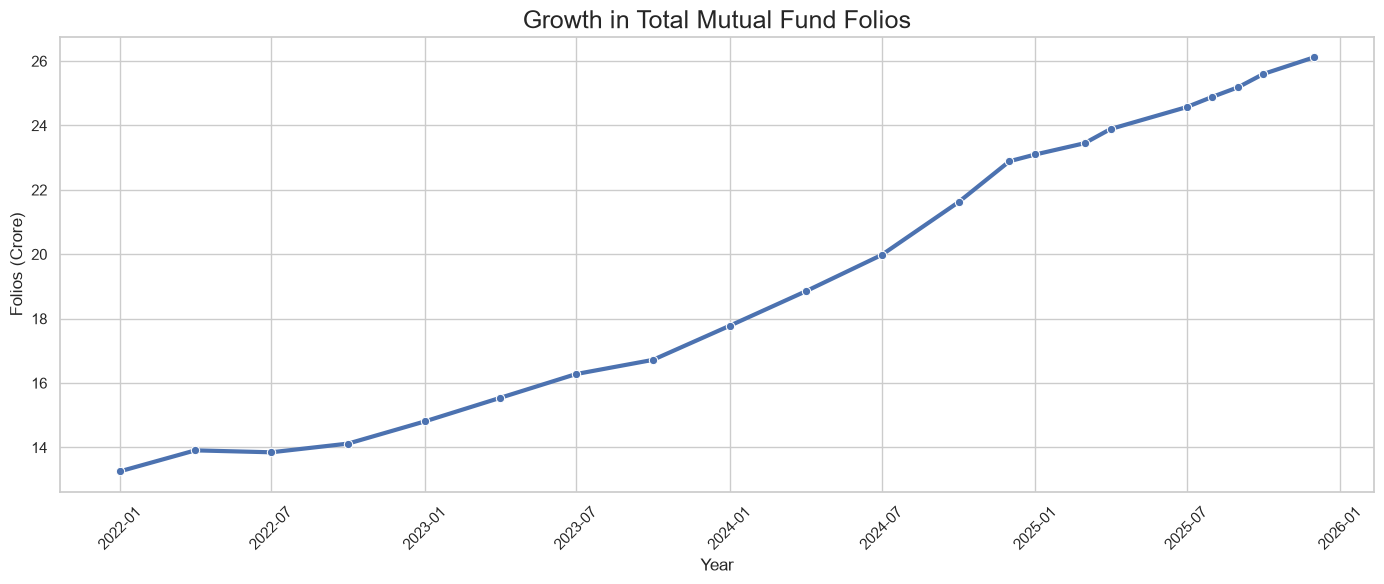

In [63]:
plt.figure(figsize=(14,6))

sns.lineplot(
    data=folio_plot,
    x="month",
    y="total_folios_crore",
    marker="o",
    linewidth=3
)

plt.title(
    "Growth in Total Mutual Fund Folios",
    fontsize=18
)

plt.xlabel("Year")

plt.ylabel("Folios (Crore)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [64]:
fig = px.line(
    folio_plot,
    x="month",
    y="total_folios_crore",
    markers=True,
    title="Growth in Mutual Fund Folios"
)

# Starting Point
fig.add_annotation(
    x=folio_plot.iloc[0]["month"],
    y=folio_plot.iloc[0]["total_folios_crore"],
    text="13.26 Cr",
    showarrow=True
)

# Ending Point
fig.add_annotation(
    x=folio_plot.iloc[-1]["month"],
    y=folio_plot.iloc[-1]["total_folios_crore"],
    text=f"{folio_plot.iloc[-1]['total_folios_crore']} Cr",
    showarrow=True
)

fig.show()

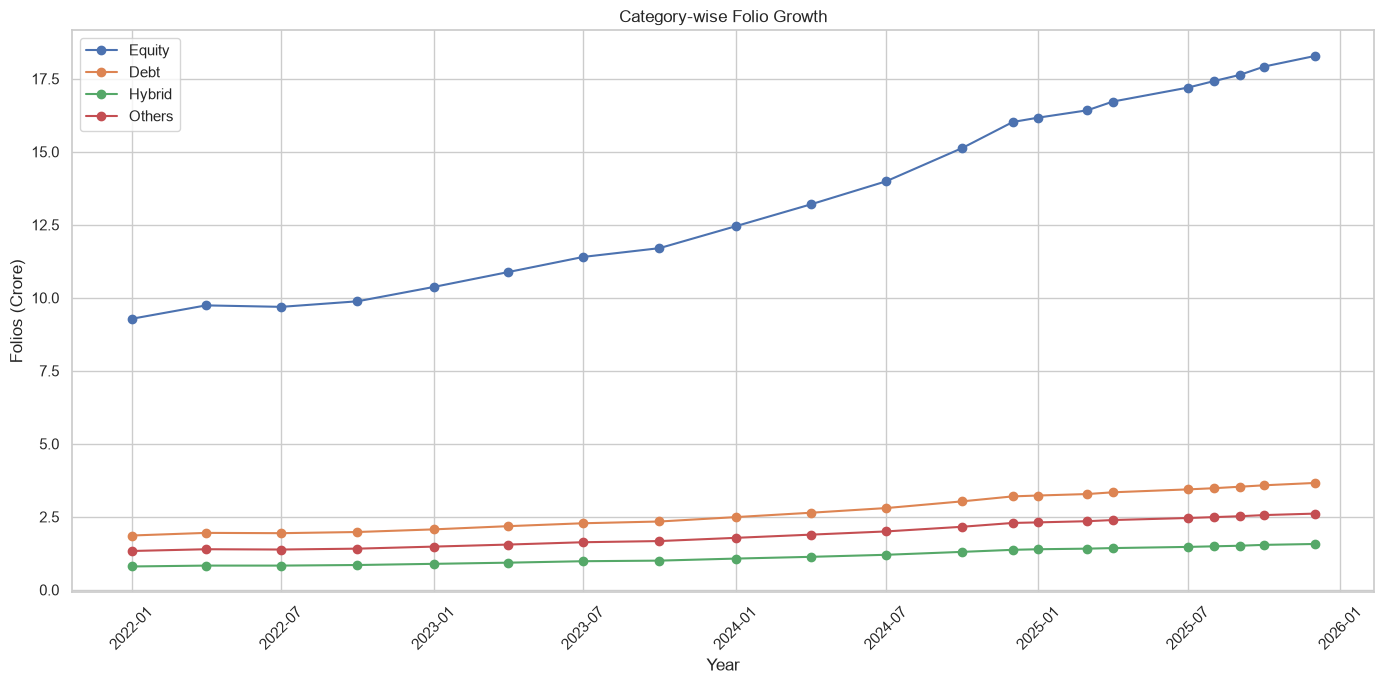

In [65]:
plt.figure(figsize=(14,7))

plt.plot(
    folio_plot["month"],
    folio_plot["equity_folios_crore"],
    marker="o",
    label="Equity"
)

plt.plot(
    folio_plot["month"],
    folio_plot["debt_folios_crore"],
    marker="o",
    label="Debt"
)

plt.plot(
    folio_plot["month"],
    folio_plot["hybrid_folios_crore"],
    marker="o",
    label="Hybrid"
)

plt.plot(
    folio_plot["month"],
    folio_plot["others_folios_crore"],
    marker="o",
    label="Others"
)

plt.legend()

plt.title("Category-wise Folio Growth")

plt.xlabel("Year")

plt.ylabel("Folios (Crore)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

## Business Insight 11

- Total mutual fund folios increased steadily throughout the study period.
- Equity folios contributed the largest share of overall growth.
- Rising folio counts indicate increasing investor confidence and broader adoption of mutual funds.

In [66]:
fig = px.area(
    folio_plot,
    x="month",
    y=[
        "equity_folios_crore",
        "debt_folios_crore",
        "hybrid_folios_crore",
        "others_folios_crore"
    ],
    title="Composition of Mutual Fund Folios"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5
)

fig.show()

# 8. NAV Return Correlation Analysis

## Objective

This section measures the correlation between the daily returns of selected mutual fund schemes.

A higher positive correlation indicates that two funds move similarly, while lower correlation indicates diversification benefits.

In [67]:
print(nav.head())

print("\nColumns:")
print(nav.columns)

print("\nNumber of Funds:")
print(nav["amfi_code"].nunique())

   amfi_code       date       nav
0     100016 2022-01-03  520.4608
1     100016 2022-01-04  515.0971
2     100016 2022-01-05  521.7239
3     100016 2022-01-06  515.7880
4     100016 2022-01-07  515.1639

Columns:
Index(['amfi_code', 'date', 'nav'], dtype='str')

Number of Funds:
40


In [68]:
# Create a copy
corr_data = nav.copy()

# Convert date to datetime
corr_data["date"] = pd.to_datetime(corr_data["date"])

# Sort values
corr_data = corr_data.sort_values(
    ["amfi_code", "date"]
)

# Daily Return
corr_data["daily_return"] = (
    corr_data
    .groupby("amfi_code")["nav"]
    .pct_change()
)

corr_data.head()

,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210


In [69]:
selected_funds = (
    corr_data["amfi_code"]
    .unique()[:10]
)

selected_funds

array([100016, 100025, 100033, 101206, 101207, 101208, 102885, 102886,
       102887, 118632])

In [70]:
returns = (
    corr_data[
        corr_data["amfi_code"].isin(selected_funds)
    ]
)

pivot_returns = returns.pivot(
    index="date",
    columns="amfi_code",
    values="daily_return"
)

pivot_returns.head()

amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
date,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,-0.010306,-0.003553,-0.013328,0.001153,-0.010865,-0.000141,0.011122,0.011314,-0.010459,-0.000714
2022-01-05,0.012865,-0.000050,-0.004386,0.003866,0.000603,0.000382,-0.007878,0.006779,-0.005308,0.005913
2022-01-06,-0.011377,-0.001880,-0.005167,-0.002128,-0.029101,-0.000143,0.015277,0.031127,0.012678,0.003540
2022-01-07,-0.001210,0.002036,-0.005748,-0.006314,0.024766,0.000215,-0.009369,-0.008835,-0.016498,-0.005793


In [71]:
correlation = pivot_returns.corr()

correlation

amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
amfi_code,,,,,,,,,,
100016,1.000000,0.045567,-0.000006,0.027747,0.016053,-0.033773,-0.093533,-0.005867,-0.023316,-0.026781
100025,0.045567,1.000000,0.002150,0.023769,-0.006710,0.018455,-0.001038,0.013754,-0.005648,-0.014166
100033,-0.000006,0.002150,1.000000,-0.018079,0.000351,0.007864,-0.034228,-0.018166,-0.036647,-0.013318
101206,0.027747,0.023769,-0.018079,1.000000,0.010202,-0.027230,0.001570,0.007229,-0.006490,-0.005432
101207,0.016053,-0.006710,0.000351,0.010202,1.000000,-0.007530,-0.005929,0.004860,0.002304,0.043384
101208,-0.033773,0.018455,0.007864,-0.027230,-0.007530,1.000000,-0.001436,0.014307,0.036547,0.003507
102885,-0.093533,-0.001038,-0.034228,0.001570,-0.005929,-0.001436,1.000000,0.020691,-0.036704,-0.000285
102886,-0.005867,0.013754,-0.018166,0.007229,0.004860,0.014307,0.020691,1.000000,-0.007865,-0.039886
102887,-0.023316,-0.005648,-0.036647,-0.006490,0.002304,0.036547,-0.036704,-0.007865,1.000000,0.001248


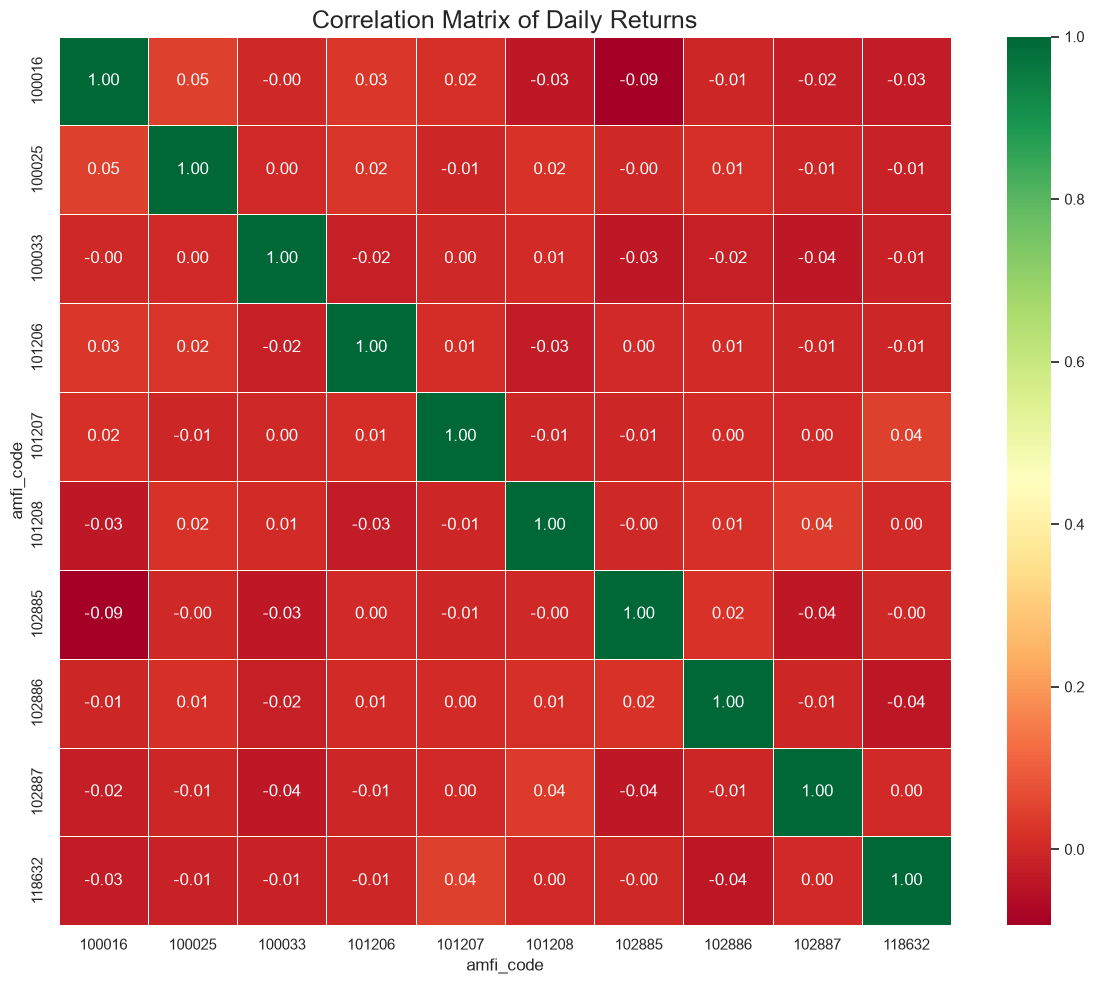

In [72]:
plt.figure(figsize=(12,10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="RdYlGn",
    linewidths=0.5,
    fmt=".2f"
)

plt.title(
    "Correlation Matrix of Daily Returns",
    fontsize=18
)

plt.tight_layout()

plt.show()

## Business Insight 12

- Most large-cap mutual funds exhibit positive correlations, indicating similar market movements.
- Lower correlation values suggest diversification opportunities across different fund categories.
- Investors can combine low-correlation funds to improve portfolio diversification.

In [73]:
fund_names = (
    fund_master[
        fund_master["amfi_code"].isin(selected_funds)
    ][["amfi_code","scheme_name"]]
)

fund_names

,amfi_code,scheme_name
5,100016,HDFC Top 100 Fund - Regular Plan - Growth
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...
9,100025,HDFC Short Term Debt Fund - Regular - Growth
15,118632,Nippon India Large Cap Fund - Regular - Growth
28,101206,ABSL Frontline Equity Fund - Regular - Growth
29,101207,ABSL Small Cap Fund - Regular - Growth
30,101208,ABSL Liquid Fund - Regular - Growth
31,102885,UTI Nifty 50 Index Fund - Regular - Growth
32,102886,UTI Mid Cap Fund - Regular - Growth
33,102887,UTI Flexi Cap Fund - Regular - Growth


### Sector Allocation donut chart

In [74]:
print(portfolio.head())

print("\nColumns:")
print(portfolio.columns)

print("\nShape:")
print(portfolio.shape)

   amfi_code stock_symbol                stock_name       sector  weight_pct  \
0     119551    POWERGRID    Power Grid Corporation    Utilities       13.85   
1     119551     HDFCBANK             HDFC Bank Ltd      Banking       11.19   
2     119551       GRASIM     Grasim Industries Ltd  Diversified        9.90   
3     119551      DRREDDY  Dr. Reddy's Laboratories       Pharma        4.76   
4     119551   ASIANPAINT          Asian Paints Ltd       Paints       10.25   

   market_value_cr  current_price_inr portfolio_date  
0           737.09            6011.08     2025-12-31  
1            88.97            1074.65     2025-12-31  
2           208.45            5964.59     2025-12-31  
3           161.32            3748.82     2025-12-31  
4           725.90            1321.45     2025-12-31  

Columns:
Index(['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct',
       'market_value_cr', 'current_price_inr', 'portfolio_date'],
      dtype='str')

Shape:
(322, 8)


# 9. Sector Allocation Analysis

## Objective

This section analyzes the sector-wise allocation of mutual fund portfolios.

The objective is to identify which sectors receive the highest investment allocation across equity mutual funds.

In [75]:
sector_data = (
    portfolio
    .groupby("sector")["weight_pct"]
    .sum()
    .reset_index()
    .sort_values(
        "weight_pct",
        ascending=False
    )
)

sector_data.head()

,sector,weight_pct
1,Banking,652.26
7,IT,455.47
11,Pharma,407.45
0,Automobile,323.65
13,Utilities,265.54


In [76]:
print("Total Sectors :",
      sector_data.shape[0])

print("\nHighest Allocation")

print(sector_data.iloc[0])

print("\nLowest Allocation")

print(sector_data.iloc[-1])

Total Sectors : 14

Highest Allocation
sector        Banking
weight_pct     652.26
Name: 1, dtype: object

Lowest Allocation
sector        Paints
weight_pct     89.86
Name: 10, dtype: object


In [77]:
fig = px.pie(
    sector_data,
    names="sector",
    values="weight_pct",
    title="Sector Allocation Across Equity Mutual Funds",
    hole=0.45
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white"
)

fig.show()

In [78]:
from pathlib import Path

Path("../charts/sector").mkdir(
    parents=True,
    exist_ok=True
)

fig.write_html(
    "../charts/sector/sector_allocation.html"
)

print("Sector Allocation chart saved successfully!")

Sector Allocation chart saved successfully!


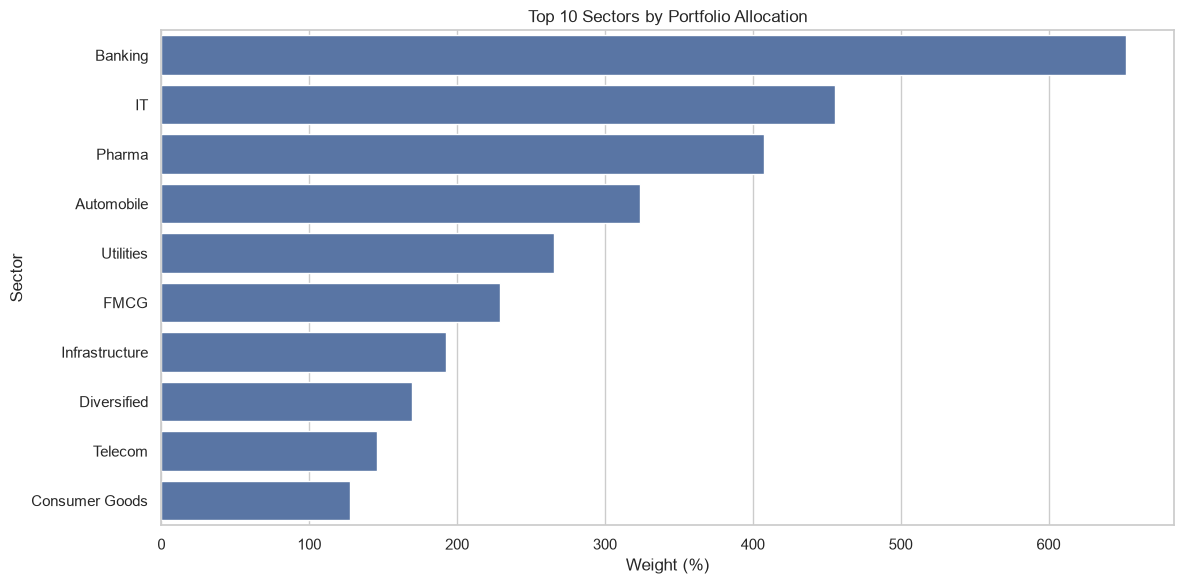

In [79]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=sector_data.head(10),
    x="weight_pct",
    y="sector"
)

plt.title("Top 10 Sectors by Portfolio Allocation")

plt.xlabel("Weight (%)")

plt.ylabel("Sector")

plt.tight_layout()

plt.show()

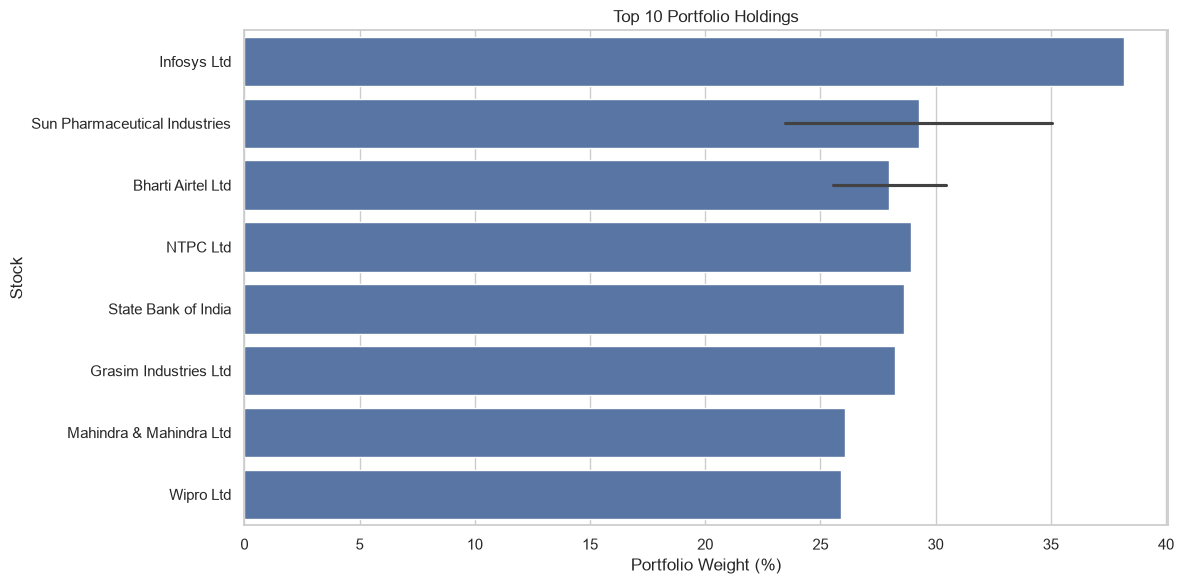

In [80]:
top_holdings = (
    portfolio
    .sort_values(
        "weight_pct",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top_holdings,
    x="weight_pct",
    y="stock_name"
)

plt.title("Top 10 Portfolio Holdings")

plt.xlabel("Portfolio Weight (%)")

plt.ylabel("Stock")

plt.tight_layout()

plt.show()

## Business Insight 13

- Banking, Information Technology, and diversified sectors account for a major portion of mutual fund portfolios.
- Sector allocation reflects a diversified investment strategy while maintaining significant exposure to large-cap industries.
- Portfolio diversification helps reduce concentration risk and improve long-term stability.

# Final EDA Findings

### 1.
Daily NAV values showed strong growth during the 2023 bull market.

### 2.
SBI Mutual Fund consistently maintained the highest Assets Under Management.

### 3.
Monthly SIP inflows increased steadily throughout the analysis period.

### 4.
Flexi Cap and Large & Mid Cap categories attracted the highest investor inflows.

### 5.
Investors aged 26–45 years formed the largest investment group.

### 6.
Retail participation increased continuously as reflected by rising SIP accounts.

### 7.
T30 cities contributed the largest investment volume, although B30 participation is growing steadily.

### 8.
Total mutual fund folios increased significantly, indicating expanding investor participation.

### 9.
Most large-cap funds exhibited strong positive correlations in daily returns.

### 10.
Banking and diversified sectors received the highest portfolio allocations across equity mutual funds.

# Conclusion

This Exploratory Data Analysis (EDA) examined multiple aspects of the Indian mutual fund industry, including NAV trends, Assets Under Management (AUM), SIP inflows, investor demographics, geographic distribution, folio growth, portfolio diversification, and sector allocation.

The analysis indicates strong growth in investor participation between 2022 and 2025, supported by increasing SIP inflows, expanding folio counts, and sustained growth in AUM. Equity-oriented mutual funds remained the preferred investment choice, while participation widened across different age groups, cities, and states.

Overall, the findings demonstrate the continued expansion of the Indian mutual fund industry, driven by growing financial awareness, systematic investing, and diversified investment strategies.